In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal

import pinner2026_jpo_code
import pinner2026_jpo_code.cross_correlation as cc

We quantify the similarities between bottom-near and surface variables by the normalized cross-correlation between two time series $a(t)$ and $b(t)$ as $\big(a \star b\big)(t^\prime)$, building on an implementation in Scipy.
$\big(a \star b\big)(t^\prime)$ is then given as
\begin{equation}
    \big(a \star b\big)(t^\prime) \overset{\text{def}}= \int_{-\infty}^{\infty} \frac{\big(a(t)-\mu_a\big) \: \big(b(t-t^\prime)-\mu_b\big)}{\sigma_a\sigma_b} \: \mathrm{d}t,
\end{equation}
with the temporal arithmetic means $\mu_a, \mu_b$ and standard deviations $\sigma_a, \sigma_b$ of the two time series.
The time lag $t^\prime$ describes the shift of one time series against another.
A positive lag $t^\prime$ means time series $a$ lags time series $b$ (i.e., the peaks in $b$ happen first).

The normalization ensures the cross-correlation at zero lag is equal to the linear correlation coefficient and through that the comparability between multiple cross-correlations.
We approximate the uncertainty of the correlation at every lag $∆ {(a \star b)}(t^\prime)$ by the standard error of the linear correlation coefficient, dependent on the degrees of freedom $n-3$ and the number of data points $n$ in the time series (Gnambs et al., 2023, Bonett et al., 2008)
\begin{equation}
   ∆ {(a \star b)}(t^\prime) = \frac{1-\Big[\big(a \star b\big)(t^\prime)\Big]^2}{\sqrt{n-3}}.
\end{equation}

### Example

In [2]:
def f(x, shift):
    x = np.asarray(x)
    x_noise = np.random.normal(-0.1, 0.1, size=x.shape)
    y_noise = np.random.normal(-0.1, 0.1, size=x.shape)
    return 1 / ((x - (shift + x_noise)) ** 2 + 0.2) + y_noise


x = np.arange(-10, 10, 0.1)
a = f(x, 0)

shift = -5
b = 2 * f(x, shift)

lags, cross_correlation = cc.get_normalized_crosscorr(a, b)
lag_time_step_in_days = 0.1
time_lags = lags * lag_time_step_in_days

time_err = 0.5  # just assumed here
corr_err = cc.get_crosscorr_standard_error(
    corr=cross_correlation, N=len(a)
)  # assumes a and b are of the same length

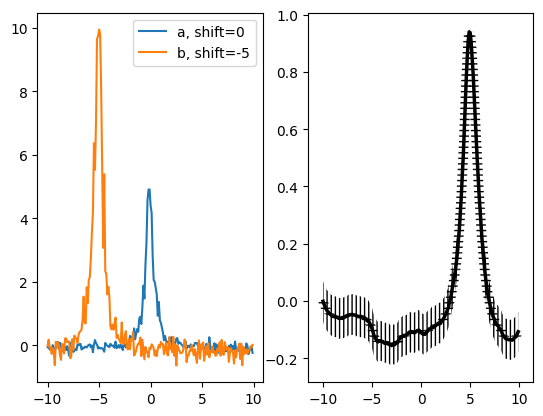

In [3]:
fig, ax = plt.subplots(ncols=2)

ax[0].plot(x, a, label="a, shift=0")
ax[0].plot(x, b, label=f"b, {shift=}")
ax[0].legend()
cc.plot_corr_with_error_bands(
    time_lags, cross_correlation, time_err, corr_err, axis=ax[1], label="", color="black"
)

> A positive lag $t^\prime$ means time series $a$ lags time series $b$ (i.e., the peaks in $b$ happen first).

# Load Data

In [4]:
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"
DERIVED_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "derived"
FIGURE_DIR: Path = pinner2026_jpo_code.FIGURE_DIR

In [5]:
def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df = df.set_index(pd.to_datetime(df["Unnamed: 0"]))
        df = df.drop("Unnamed: 0", axis="columns")
    # Convert back to complex numbers
    # https://stackoverflow.com/questions/18919699/python-pandas-complex-number
    # for i,col in enumerate(df.columns):
    #     # basically, if column is complex
    #     if not is_numeric_dtype(df[col]):
    #         df[col] = df[col].apply(lambda x: complex(x))
    df = df.fillna(0)
    return df


def read_csv(path):
    csv = pd.read_csv(path)
    return clean_csv(csv)

In [6]:
surface_stress = pd.read_csv(INTERIM_DATA_DIR / "daily_momentum_transfer.csv")
surface_stress = surface_stress.set_index(pd.to_datetime(surface_stress["Unnamed: 0"]))
surface_stress = surface_stress.drop("Unnamed: 0", axis="columns")
for _i, col in enumerate(surface_stress.columns):
    surface_stress[col] = surface_stress[col].str.replace("i", "j").apply(lambda x: complex(x))
surface_stress_at_C = surface_stress["C"].iloc[8:-76].abs().rolling("14D").mean()
surface_stress_at_C

Unnamed: 0
2017-02-12    0.027935
2017-02-17    0.017155
2017-02-22    0.015575
2017-02-27    0.033445
2017-03-04    0.073273
                ...   
2018-11-24    0.039638
2018-11-29    0.059881
2018-12-04    0.086653
2018-12-09    0.080408
2018-12-14    0.064408
Name: C, Length: 135, dtype: float64

In [7]:
velocity = pd.read_csv(INTERIM_DATA_DIR / "velo_at_C.csv")
velocity = velocity.set_index(pd.to_datetime(velocity["time_2350"]))
velocity = velocity.drop("time_2350", axis="columns")
velocity["2350"] = velocity["2350"].apply(lambda x: complex(x))
# 5 day resampled, absolute value and time shifted, as resample uses the left bin edge for labeling
mean_flow = (
    pd.Series(index=velocity.index + pd.Timedelta(hours=48), data=velocity["2350"].values)
    .abs()
    .resample("5D")
    .mean()
    .rolling("14D")
    .mean()
)
mean_flow

time_2350
2017-01-28    0.083443
2017-02-02    0.094615
2017-02-07    0.090597
2017-02-12    0.083021
2017-02-17    0.078409
                ...   
2019-01-08    0.071975
2019-01-13    0.080419
2019-01-18    0.093266
2019-01-23    0.093530
2019-01-28    0.074432
Freq: 5D, Length: 147, dtype: float64

In [8]:
nsquared = read_csv(INTERIM_DATA_DIR / "N2_at_C_2350m.csv")
nsquared = (
    pd.Series(index=nsquared.index + pd.Timedelta(hours=48), data=nsquared.values.flatten())
    .resample("5D")
    .mean()
    .rolling("14D")
    .mean()
)
nsquared
# truncated_nsquared = nsquared.resample("5D", origin=smoothed_hke.index[0]).mean().loc[smoothed_hke.index[0]:smoothed_hke.index[-1]]
# truncated_nsquared.plot(ax=ax)
# truncated_nsquared

Unnamed: 0
2017-01-28    0.000002
2017-02-02    0.000002
2017-02-07    0.000002
2017-02-12    0.000002
2017-02-17    0.000002
                ...   
2019-01-08    0.000002
2019-01-13    0.000002
2019-01-18    0.000002
2019-01-23    0.000002
2019-01-28    0.000002
Freq: 5D, Length: 147, dtype: float64

In [9]:
hke = pd.read_csv(INTERIM_DATA_DIR / "HKE.csv", index_col=0, header=[0, 1])
hke.index = pd.to_datetime(hke.index).floor("D")
# results.index = multi_index
hke = hke["C", "2350"].rolling("14D").mean()

In [10]:
dissip_IGW_at_C = pd.read_csv(
    DERIVED_DATA_DIR / "wave_induced_dissipation_rate_time_series_at_C.csv"
)
dissip_IGW_at_C = dissip_IGW_at_C.set_index(pd.to_datetime(dissip_IGW_at_C["Unnamed: 0"]))
dissip_IGW_at_C = dissip_IGW_at_C.drop("Unnamed: 0", axis="columns").squeeze().rolling("14D").mean()
dissip_IGW_at_C

Unnamed: 0
2017-02-12    8.252667e-10
2017-02-17    8.480725e-10
2017-02-22    8.424928e-10
2017-02-27    8.809639e-10
2017-03-04    1.105369e-09
                  ...     
2018-12-24    9.670707e-10
2018-12-29    1.027777e-09
2019-01-03    1.123878e-09
2019-01-08    1.232041e-09
2019-01-13    1.222098e-09
Name: 0, Length: 141, dtype: float64

# Cross Correlations

[-70 -69 -68 -67 -66 -65 -64 -63 -62 -61 -60 -59 -58 -57 -56 -55 -54 -53
 -52 -51 -50 -49 -48 -47 -46 -45 -44 -43 -42 -41 -40 -39 -38 -37 -36 -35
 -34 -33 -32 -31 -30 -29 -28 -27 -26 -25 -24 -23 -22 -21 -20 -19 -18 -17
 -16 -15 -14 -13 -12 -11 -10  -9  -8  -7  -6  -5  -4  -3  -2  -1   0   1
   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19
  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36  37
  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70] [-2.06891043e-01 -1.93225689e-01 -1.53780215e-01 -9.45240893e-02
 -3.29662203e-02  1.25812268e-02  4.03632325e-02  4.11494928e-02
  2.89134790e-02  9.01406811e-03  2.85236175e-05 -7.29699473e-03
 -3.29873311e-03 -7.09366584e-03 -1.57246219e-02 -4.70322847e-02
 -8.13261060e-02 -1.10388454e-01 -1.15788126e-01 -1.10035742e-01
 -1.02775902e-01 -1.09634550e-01 -1.28760063e-01 -1.49402954e-01
 -1.52732176e-01 -1.31776649e-01 -7.2

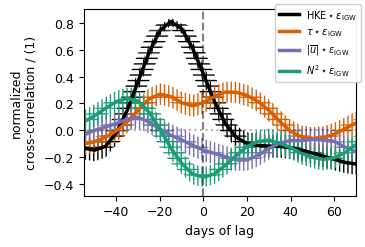

In [11]:
cm = 1 / 2.54  # centimeters in inches
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "font.size": 9})

fig, ax = plt.subplots(ncols=1, figsize=(9 * cm, 6 * cm), layout="constrained")
ax = ["", ax]
ax[1].axhline(0, color="k", alpha=0.3, ls=":")
ax[1].axvline(0, color="k", alpha=0.5, ls="--")

# ax[1].xaxis.set_major_locator(mticker.FixedLocator(np.arange(-100, 150, 50)))
# ax[1].xaxis.set_minor_locator(mticker.FixedLocator(np.arange(-100, 110, 25)))


a = hke.iloc[3:]
b = dissip_IGW_at_C.iloc[:-3]
assert np.all(a.index == b.index)
lags, crosscorr = cc.get_normalized_crosscorr(a.values.flatten(), b.values.flatten())
time_lags = lags * dissip_IGW_at_C.index.diff().mean().days
N = len(dissip_IGW_at_C)
label = "$\\text{HKE} \\star \\varepsilon_\\mathrm{IGW}$"
color = "k"
cc.plot_corr_with_error_bands(
    time_lags,
    crosscorr,
    x_err=5,
    y_err=cc.get_crosscorr_standard_error(crosscorr, N),
    axis=ax[1],
    label=label,
    color=color,
)  # , plot_errorbars=False)


a = surface_stress_at_C.iloc[:]
b = dissip_IGW_at_C.loc[: a.index[-1]]
assert np.all(a.index == b.index)
lags, crosscorr = cc.get_normalized_crosscorr(a.values.flatten(), b.values.flatten())
time_lags = lags * dissip_IGW_at_C.index.diff().mean().days
N = len(dissip_IGW_at_C)
label = "$\\tau \\star \\varepsilon_\\mathrm{IGW}$"
color = "#d95f02"
cc.plot_corr_with_error_bands(
    time_lags,
    crosscorr,
    x_err=5,
    y_err=cc.get_crosscorr_standard_error(crosscorr, N),
    axis=ax[1],
    label=label,
    color=color,
)  # , plot_errorbars=False)

a = mean_flow.iloc[3:-3]
b = dissip_IGW_at_C.iloc[:]
print(a, b)
assert np.all(a.index == b.index)
lags, crosscorr = cc.get_normalized_crosscorr(a.values.flatten(), b.values.flatten())
time_lags = lags * dissip_IGW_at_C.index.diff().mean().days
N = len(dissip_IGW_at_C)
label = "$|\\overline{u}| \\star \\varepsilon_\\mathrm{IGW}$"
color = "#7570b3"
cc.plot_corr_with_error_bands(
    time_lags,
    crosscorr,
    x_err=5,
    y_err=cc.get_crosscorr_standard_error(crosscorr, N),
    axis=ax[1],
    label=label,
    color=color,
)  # , plot_errorbars=False)

print(lags, crosscorr)

a = nsquared.iloc[3:-3]
b = dissip_IGW_at_C.iloc[:]
assert np.all(a.index == b.index)
lags, crosscorr = cc.get_normalized_crosscorr(a.values.flatten(), b.values.flatten())
time_lags = lags * dissip_IGW_at_C.index.diff().mean().days
N = len(dissip_IGW_at_C)
label = "$N^2 \\star \\varepsilon_\\mathrm{IGW}$"
color = "#1b9e77"
cc.plot_corr_with_error_bands(
    time_lags,
    crosscorr,
    x_err=5,
    y_err=cc.get_crosscorr_standard_error(crosscorr, N),
    axis=ax[1],
    label=label,
    color=color,
)  # , plot_errorbars=False)

# a = surface_stress_at_C.iloc[8:-76]
# b = hke.iloc[3:-3]
# # a = surface_stress_at_C.iloc[8:-73]
# # b = hke.iloc[3:]
# assert np.all(a.index==b.index )
# lags, cross = cross_corr(a.values, b.values.flatten())
# x= lags * dissip_IGW_at_C.index.diff().mean().days
# y= cross
# N=len(surface_stress_at_C)
# label="$\\tau \\star \\text{HKE}$"
# color="tab:red"
# plot_corr_with_xy_error_bands(x,y,N,axis=ax[1],label=label,color=color,plot_errorbars=False)

# a = _surface_stress_at_C.iloc[8:-73]
# b = hke.iloc[3:]
# assert np.all(a.index==b.index )
# lags, cross = cross_corr(a.values, b.values.flatten())
# x= lags * dissip_IGW_at_C.index.diff().mean().days
# y= cross
# N=len(surface_stress_at_C)
# label="$2. \\tau \\star \\text{HKE}$"
# color="tab:blue"
# plot_corr_with_xy_error_bands(x,y,N,axis=ax[1],label=label,color=color,plot_errorbars=False)

ax[1].set_xlim(-55, 70)
ax[1].set_xlabel("days of lag")
ax[1].set_ylabel("normalized\ncross-correlation / (1)")
# #ax[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
fig.legend(fontsize=7, loc="upper right", framealpha=0.95)  # , ncols=2)
# fig.savefig("surface_dissip_corr.pdf")

In [18]:
a = mean_flow.iloc[3:-3]
b = dissip_IGW_at_C.iloc[:]
print(a, b)

time_2350
2017-02-12    0.083021
2017-02-17    0.078409
2017-02-22    0.096607
2017-02-27    0.116557
2017-03-04    0.111483
                ...   
2018-12-24    0.075326
2018-12-29    0.073068
2019-01-03    0.070721
2019-01-08    0.071975
2019-01-13    0.080419
Freq: 5D, Length: 141, dtype: float64 Unnamed: 0
2017-02-12    8.252667e-10
2017-02-17    8.480725e-10
2017-02-22    8.424928e-10
2017-02-27    8.809639e-10
2017-03-04    1.105369e-09
                  ...     
2018-12-24    9.670707e-10
2018-12-29    1.027777e-09
2019-01-03    1.123878e-09
2019-01-08    1.232041e-09
2019-01-13    1.222098e-09
Name: 0, Length: 141, dtype: float64


In [12]:
help(cc.plot_corr_with_error_bands)

Help on function plot_corr_with_error_bands in module pinner2026_jpo_code.cross_correlation:

plot_corr_with_error_bands(lags, corr, x_err, y_err, axis, label, color)



In [13]:
help(cc)

Help on module pinner2026_jpo_code.cross_correlation in pinner2026_jpo_code:

NAME
    pinner2026_jpo_code.cross_correlation

FUNCTIONS
    get_crosscorr_standard_error(corr, N)

    get_normalized_crosscorr(a, b)

    plot_corr_with_error_bands(lags, corr, x_err, y_err, axis, label, color)

    plot_xy_errorbands(
        x,
        y,
        x_errors,
        y_errors,
        x_style: dict | None = None,
        y_style: dict | None = None,
        x_label: str = '',
        y_label: str = '',
        plot_errorbars: bool = False,
        ax: mpl.axes.Axes = None
    )

FILE
    c:\users\opinner\desktop\python\pinner2026_jpo_code\src\pinner2026_jpo_code\cross_correlation.py




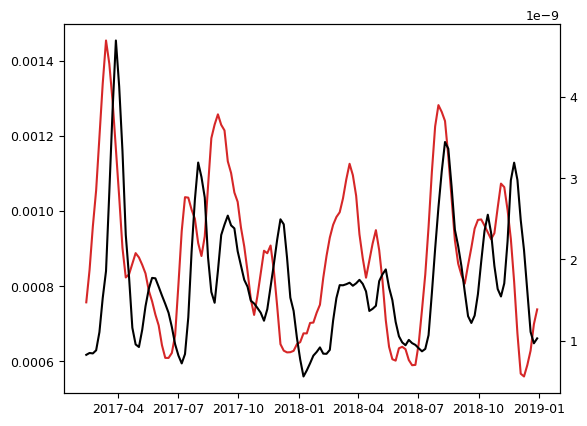

In [14]:
a = hke.iloc[3:]
b = dissip_IGW_at_C.iloc[:-3]
plt.plot(a.index, a, "tab:red")
ax2 = plt.gca().twinx()
# ax2.plot(dissip_IGW_at_C.index,dissip_IGW_at_C,"k")
ax2.plot(b.index, b, "k")
# c = smooth(nsquared.values.flatten(),8)
# ax2.plot(nsquared.index[3:],(c-np.mean(c))[3:],"k")

array([ 0.0275348 ,  0.00337264, -0.03088996, -0.07368911, -0.12311673,
       -0.17479641, -0.22113926, -0.2571182 , -0.28239283, -0.29515627,
       -0.28795935, -0.25776742, -0.2067722 , -0.14094294, -0.06755307,
        0.00100276,  0.04925537,  0.07132589,  0.06779802,  0.04498105,
        0.01194702, -0.01777215, -0.03255121, -0.03058587, -0.01329274,
        0.01325352,  0.0420284 ,  0.06170368,  0.06918301,  0.06711031,
        0.06227603,  0.05326249,  0.04262084,  0.02807345,  0.01298299,
       -0.00577071, -0.02014673, -0.02330089, -0.01073486,  0.00979677,
        0.02856302,  0.03523725,  0.02344328, -0.00928484, -0.05119936,
       -0.08865709, -0.11173147, -0.12243568, -0.12377156, -0.12131936,
       -0.11743472, -0.11430781, -0.10646625, -0.09325409, -0.07916497,
       -0.07261021, -0.08010763, -0.10149656, -0.13154986, -0.14785593,
       -0.1193466 , -0.01945335,  0.15063739,  0.36367542,  0.57969516,
        0.74398478,  0.81073921,  0.75735612,  0.61176338,  0.41

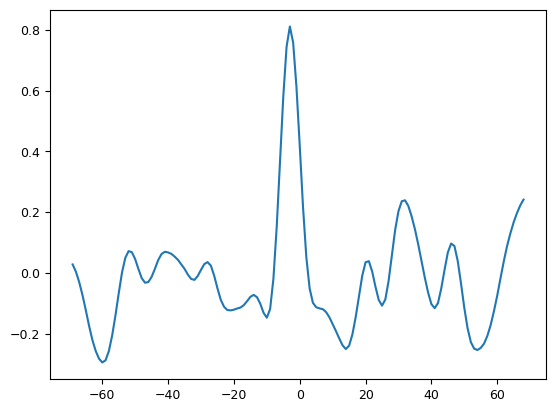

In [15]:
lags, cross = cc.get_normalized_crosscorr(a.values, b.values)
plt.plot(lags, cross)
cross

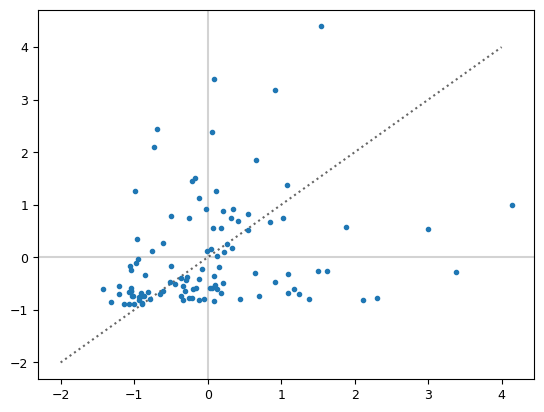

In [16]:
plt.axhline(0, color="lightgrey")
plt.axvline(0, color="lightgrey")
plt.plot(np.arange(-2, 5), np.arange(-2, 5), ls=":", color="k", alpha=0.6)

x = dissip_IGW_at_C.values.flatten()[:-33]
y = surface_stress["C"].abs().iloc[8:-103].values
plt.plot((x - np.nanmean(x)) / np.nanstd(x), (y - np.nanmean(y)) / np.nanstd(y), ".")

# , y-np.nanmean(y), 'same') / (np.nanstd(x) * np.nanstd(y))

In [17]:
np.corrcoef(dissip_IGW_at_C.values.flatten()[:-33], surface_stress["C"].abs().iloc[8:-103].values)

array([[1.       , 0.2467996],
       [0.2467996, 1.       ]])